# NumPy Data Manipulation

Data rarely arrives in the shape that an analysis or a model needs. This lesson changes the **structure** of arrays: reshape, transpose, join, split, add dimensions, sort and find unique values.

**After this lesson you can:**

1. Reshape arrays and use `-1` to infer a dimension.
2. Transpose and swap axes.
3. Join arrays (`concatenate`, `stack`) and split them.
4. Add dimensions with `np.newaxis`, and sort, deduplicate and count values.

**Data:** Seattle daily weather, 2012–2015.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads pinned public datasets

weather = pd.read_csv(datasets.fetch("seattle-weather.csv"), parse_dates=["date"])   # NOAA daily weather, Seattle

w = weather[~((weather["date"].dt.month == 2) & (weather["date"].dt.day == 29))]
temp = w["temp_max"].to_numpy()          # 1-D, 1,460 days
print(temp.shape)

(1460,)


## 1. Reshape

`reshape` reads the elements in order (row by row, "C order") and fills a new shape with the same number of elements. Use `-1` for one dimension and NumPy computes it. Reshape returns a view when possible.

In [2]:
by_year = temp.reshape(4, 365)
by_week = temp.reshape(4, 365)[:, :364].reshape(4, 52, 7)        # drop day 365 so 52 weeks x 7 days fit
print("by_year:", by_year.shape, "| by_week:", by_week.shape, "| reshape(-1, 73):", temp.reshape(-1, 73).shape)
try:
    temp.reshape(3, -1)
except ValueError as err:
    print("reshape(3, -1) ->", err)

weekly_mean = by_week.mean(axis=2)          # average over the 7 days of each week
print("weekly means:", weekly_mean.shape)

by_year: (4, 365) | by_week: (4, 52, 7) | reshape(-1, 73): (20, 73)
reshape(3, -1) -> cannot reshape array of size 1460 into shape (3,newaxis)
weekly means: (4, 52)


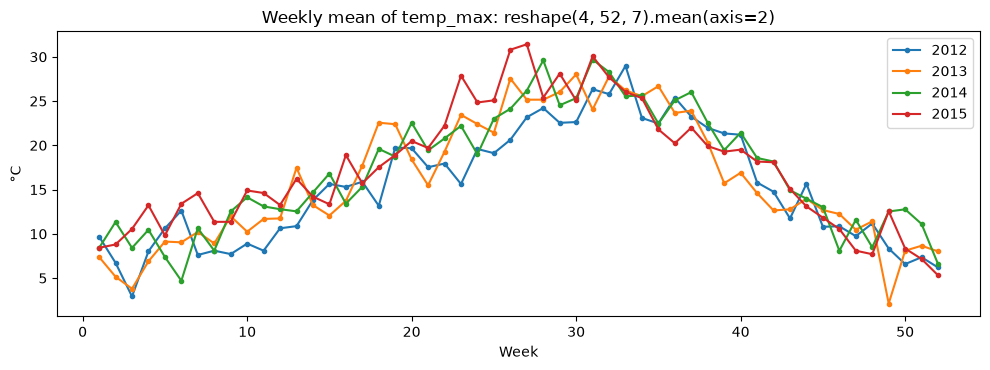

In [3]:
fig, ax = plt.subplots(figsize=(10, 3.8))
for i, year in enumerate([2012, 2013, 2014, 2015]):
    ax.plot(range(1, 53), weekly_mean[i], marker=".", label=str(year))
ax.set(title="Weekly mean of temp_max: reshape(4, 52, 7).mean(axis=2)", xlabel="Week", ylabel="°C")
ax.legend()
plt.tight_layout()
plt.show()

## 2. Axes and Transpose

An **axis** is one dimension. Aggregations take `axis=` to say which dimension disappears: in a `(4, 52, 7)` array, `axis=2` averages over days, `axis=0` over years. `.T` (transpose) reverses the axes; `np.swapaxes` and `np.moveaxis` move single axes. `ravel()` flattens to 1-D (a view if possible); `flatten()` always copies.

In [4]:
print("mean over years (axis=0)  :", by_week.mean(axis=0).shape, "-> one value per week and weekday")
print("mean over weeks (axis=1)  :", by_week.mean(axis=1).shape, "-> one value per year and weekday")
print("transpose of (4, 365)     :", by_year.T.shape)
print("moveaxis(by_week, 2, 0)   :", np.moveaxis(by_week, 2, 0).shape)
print("ravel shares memory       :", np.shares_memory(by_year.ravel(), by_year),
      "| flatten shares memory:", np.shares_memory(by_year.flatten(), by_year))

mean over years (axis=0)  : (52, 7) -> one value per week and weekday
mean over weeks (axis=1)  : (4, 7) -> one value per year and weekday
transpose of (4, 365)     : (365, 4)
moveaxis(by_week, 2, 0)   : (7, 4, 52)
ravel shares memory       : True | flatten shares memory: False


## 3. Join and Split

| Function | Joins along |
| :--- | :--- |
| `np.concatenate([a, b], axis=k)` | an **existing** axis |
| `np.stack([a, b], axis=k)` | a **new** axis |
| `np.vstack`, `np.hstack`, `np.column_stack` | shortcuts for rows / columns |
| `np.split(a, n)`, `np.array_split(a, n)` | splits into parts (`array_split` allows unequal parts) |

In [5]:
tmax = w["temp_max"].to_numpy()
tmin = w["temp_min"].to_numpy()
both = np.stack([tmin, tmax], axis=1)                  # (1460, 2): one row per day, columns min and max
longer = np.concatenate([tmin, tmax])                  # (2920,): one long vector
print("stack axis=1:", both.shape, "| concatenate:", longer.shape, "| column_stack:", np.column_stack([tmin, tmax]).shape)

quarters = np.array_split(tmax, 4)                     # 4 roughly equal parts
print("array_split sizes:", [len(q) for q in quarters])
train, test = np.split(tmax, [1095])                   # first 3 years / last year
print("train/test split for a forecasting model:", train.shape, test.shape)

stack axis=1: (1460, 2) | concatenate: (2920,) | column_stack: (1460, 2)
array_split sizes: [365, 365, 365, 365]
train/test split for a forecasting model: (1095,) (365,)


## 4. New Axes, Sorting, Unique Values

`np.newaxis` (or `None`) inserts a dimension of size 1, for example to turn a vector into a column. This is the key to broadcasting (Lesson 05).

In [6]:
v = np.array([1.0, 2.0, 3.0])
print("v:", v.shape, "| v[:, np.newaxis]:", v[:, np.newaxis].shape, "| v[np.newaxis, :]:", v[np.newaxis, :].shape)

kinds = w["weather"].to_numpy()
labels, counts = np.unique(kinds, return_counts=True)
order = np.argsort(counts)[::-1]
print("\nweather types:", dict(zip(labels[order].tolist(), counts[order].tolist())))

sorted_temps = np.sort(tmax)
print("median by sorting:", sorted_temps[len(sorted_temps) // 2], "| np.median:", np.median(tmax))
codes = np.searchsorted(labels, kinds)               # labels -> integer codes (labels are sorted)
print("integer codes of the first days:", codes[:8], "->", labels[codes[:8]].tolist())

v: (3,) | v[:, np.newaxis]: (3, 1) | v[np.newaxis, :]: (1, 3)

weather types: {'rain': 641, 'sun': 640, 'fog': 101, 'drizzle': 53, 'snow': 25}
median by sorting: 15.6 | np.median: 15.6
integer codes of the first days: [0 2 2 2 2 2 2 4] -> ['drizzle', 'rain', 'rain', 'rain', 'rain', 'rain', 'rain', 'sun']


Turning labels into integer codes is what pandas does with the `category` dtype (Lesson 14) and what models need as input (M10).

*Insight: Before writing a loop over a dimension, try to reshape the array so that the dimension becomes an axis, then aggregate with `axis=`. Most "group into weeks/blocks/windows" tasks become one reshape and one reduction.*

## Real-World Use Case or Analogy

Reshaping is like **rearranging eggs** from a long row into an egg box: the eggs stay the same, only the grid changes. Every box must be completely filled, which is why 1,460 days fit into 4 × 365 but not into 3 rows.

Deep-learning code reshapes all the time: a batch of images is `(batch, channels, height, width)`, a transformer splits embeddings into heads with `reshape` and `transpose` (M26). Shape errors are the most common bug in such code, so it pays to print shapes at every step.